# Bill Gates entra en un bar

**Jornada 2 · Bloque 2.2 · Centro y dispersión**

**Cómo usarlo.** En Google Colab: menú *Entorno de ejecución → Ejecutar todo* (en inglés, *Runtime → Run all*); la primera vez tarda unos segundos en descargar los datos del curso. En Jupyter: *Ejecutar → Ejecutar todo*. Luego mueve los controles. No hace falta tocar el código: está escondido y solo carga los datos y dibuja. Si quieres verlo, pulsa los tres puntos que aparecen en las celdas ocultas.

In [1]:
# Preparación: busca la carpeta del proyecto, carga el estilo del curso y los datos.
# No hace falta tocar nada.
import sys
from pathlib import Path


def buscar_proyecto():
    """La carpeta que contiene datos/, scripts/estilo.py y cuadernos/laboratorio.py."""
    aqui = Path.cwd()
    candidatas = [aqui, *aqui.parents,
                  Path("/content/cursos-analitica-datos"),               # Colab, subida a mano
                  Path("/content/drive/MyDrive/cursos-analitica-datos")]  # Colab, desde Drive
    for carpeta in candidatas:
        if (carpeta / "scripts" / "estilo.py").exists() and (carpeta / "cuadernos" / "laboratorio.py").exists():
            return carpeta
    if "google.colab" in sys.modules:  # en Colab, descarga una vez el material público del curso
        import subprocess
        destino = Path("/content/curso-analitica-cuadernos")
        if not destino.exists():
            subprocess.run(["git", "clone", "--quiet", "--depth", "1",
                            "https://github.com/castrorbea/curso-analitica-cuadernos.git", str(destino)], check=True)
        return destino
    raise FileNotFoundError("No encuentro el proyecto: abre este cuaderno desde la carpeta cuadernos/.")


PROYECTO = buscar_proyecto()
DATOS = PROYECTO / "datos"
for ruta in (PROYECTO / "scripts", PROYECTO / "cuadernos"):  # ../scripts y la carpeta de este cuaderno
    if str(ruta) not in sys.path:
        sys.path.insert(0, str(ruta))

import ipywidgets as widgets
from IPython.display import display

import estilo  # paleta, tipografía y formato numérico español del curso
import laboratorio as lab  # cálculos y gráficos de estos cuadernos

try:  # en Google Colab, los controles necesitan activar este gestor
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

ESTILO = {"description_width": "initial"}
BOTONES = {"description_width": "initial", "button_width": "auto"}

clientes = lab.cargar_bar(DATOS)
horas = lab.cargar_incidencias(DATOS)
print(f"Datos listos: {len(clientes)} clientes habituales del bar y {len(horas):,} incidencias".replace(",", "."))

Datos listos: 30 clientes habituales del bar y 2.000 incidencias


## La pregunta

En un bar hay 30 clientes con sueldos corrientes. Entra Bill Gates. De repente, el cliente medio es
milmillonario, aunque nadie ha cobrado un euro más y la caña cuesta lo mismo. ¿A quién creemos: a la
media o a la mediana?

## El experimento

Mueve los ingresos de cada recién llegado (de 0 a 50.000 millones de euros, en saltos que se van
multiplicando) y cuántos entran. El estado inicial es el del curso: entra un solo milmillonario.
La mediana va en azul; la media, en naranja.

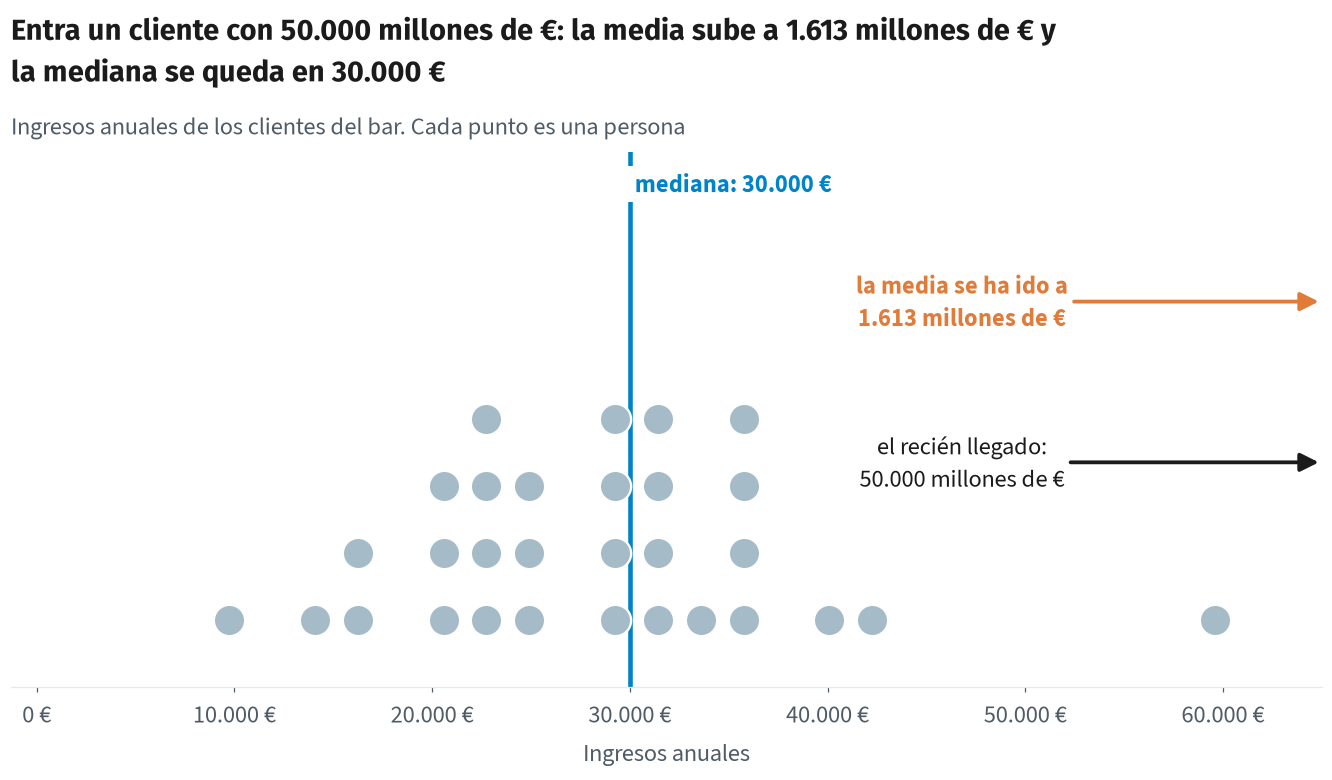

In [2]:
# El experimento: entran clientes muy ricos (o muy pobres) en el bar.
ingresos = widgets.SelectionSlider(
    options=lab.opciones_ingresos(), value=5e10, continuous_update=False,
    description="Ingresos de cada recién llegado (€ al año):", style=ESTILO,
    layout=widgets.Layout(width="700px"))
cuantos = widgets.IntSlider(value=1, min=0, max=10, continuous_update=False,
                            description="¿Cuántos entran?", style=ESTILO, layout=widgets.Layout(width="500px"))


def dibujar(ingresos, cuantos):
    lab.mostrar(lab.dibujar_bar(clientes, ingresos, cuantos))


grafico = widgets.interactive_output(dibujar, {"ingresos": ingresos, "cuantos": cuantos})
display(widgets.VBox([ingresos, cuantos, grafico]))

## Segunda parte: incidencias con cola larga

2.000 incidencias. La mayoría se resuelve en unas horas; unas pocas tardan semanas. Elige un percentil
y decide si quitas las que pasan de una semana. El estado inicial es el del curso: percentil 90 y todas
las incidencias.

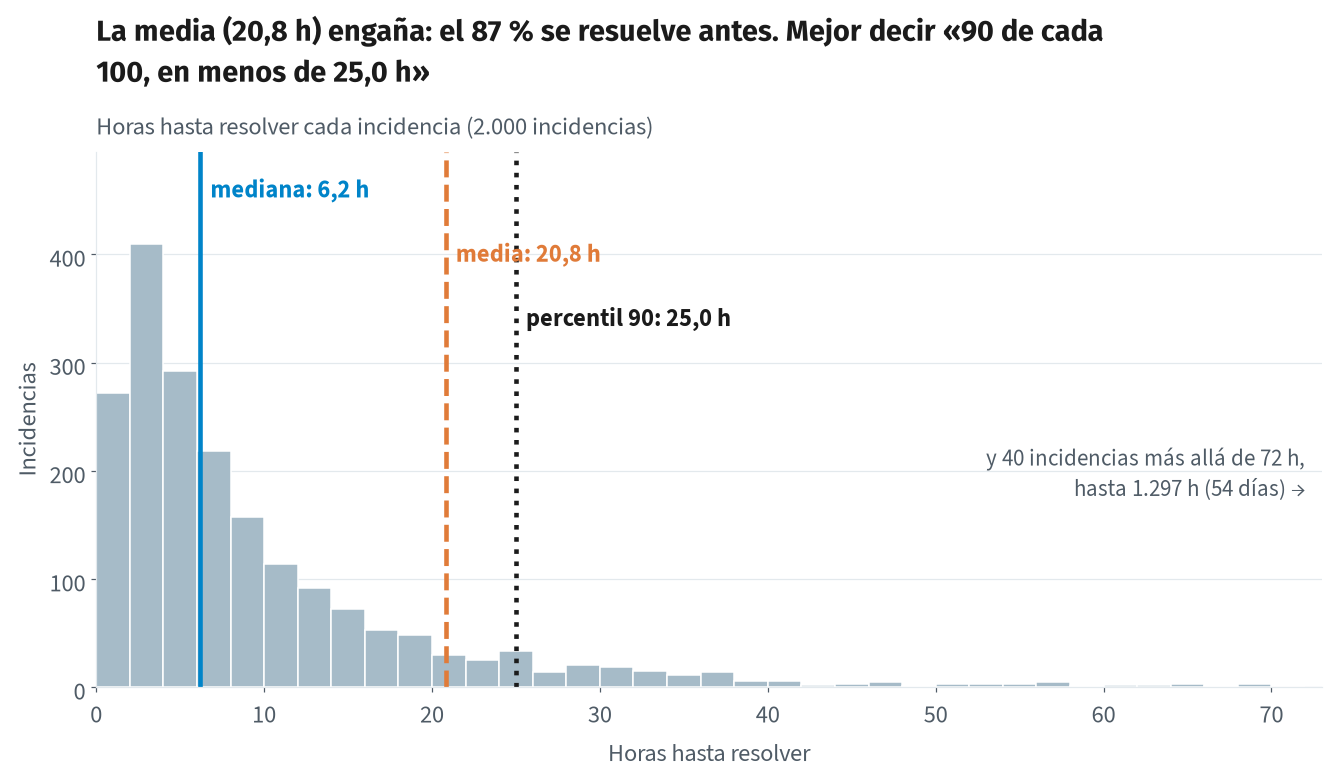

In [3]:
# La cola larga: media, mediana y percentiles de los tiempos de resolución.
percentil = widgets.IntSlider(value=90, min=50, max=99, continuous_update=False,
                              description="Percentil:", style=ESTILO, layout=widgets.Layout(width="500px"))
quitar = widgets.Checkbox(value=False, description="Quitar las que pasan de una semana", style=ESTILO)


def dibujar_cola(percentil, quitar):
    lab.mostrar(lab.dibujar_incidencias(horas, percentil, quitar))


grafico_cola = widgets.interactive_output(dibujar_cola, {"percentil": percentil, "quitar": quitar})
display(widgets.VBox([percentil, quitar, grafico_cola]))

## Qué observar

**En el bar**

1. ¿Hasta dónde hay que subir los ingresos del recién llegado para que la media deje de parecerse a
   cualquier cliente del bar?
2. ¿Cuántos «ricos» tienen que entrar para que la mediana se mueva de verdad?
3. ¿Y si los que entran no ganan nada (0 €)? ¿Cuál de las dos medidas se entera?

**En las incidencias**

4. ¿Qué porcentaje de incidencias se resuelve antes que «la media»? ¿Es buena cifra para prometer un plazo?
5. Quita las incidencias que pasan de una semana: ¿qué se mueve mucho y qué casi nada?
6. «El plazo medio es de 20,8 horas» frente a «9 de cada 10, en menos de 25 horas». ¿Cuál le dirías a
   un cliente?

## Mensaje clave

> **Antes de dar una media, mira si hay un Bill Gates en el bar.**

Con colas largas, la mediana y los percentiles cuentan mejor lo que le pasa a la mayoría.

## Para curiosos

En el avanzado, los tiempos de resolución se estudian con técnicas de supervivencia, que tienen en cuenta
también las incidencias que todavía no se han cerrado.